DEGRADACIÓN DE NEUMÁTICOS F1: LAD vs MÍNIMOS CUADRADOS

--- PASO 1: DATOS ---
Vuelta | Tiempo (s)
-------------------------
   1   |  93.52
   2   |  93.61
   3   |  93.66
   4   |  93.78
   5   |  93.81
   6   |  96.95 <- OUTLIER (tráfico)
   7   |  93.97
   8   |  94.05
   9   |  94.12
  10   |  94.18
  11   |  94.31
  12   |  94.36

--- PASO 2: MÍNIMOS CUADRADOS (con outlier) ---
  β0 = 93.7702 s
  β1 = 0.0651 s/vuelta

--- PASO 3: MÍNIMOS CUADRADOS (sin outlier) ---
  β0 = 93.4468 s
  β1 = 0.0758 s/vuelta

--- PASO 4: LAD (regresión robusta) ---
Modelo: min Σ(u_i + v_i)
s.a. (β0+ - β0-) + (β1+ - β1-)*n_i + u_i - v_i = t_i
  β0 = 93.4443 s
  β1 = 0.0757 s/vuelta

--- PASO 5: GRÁFICO ---


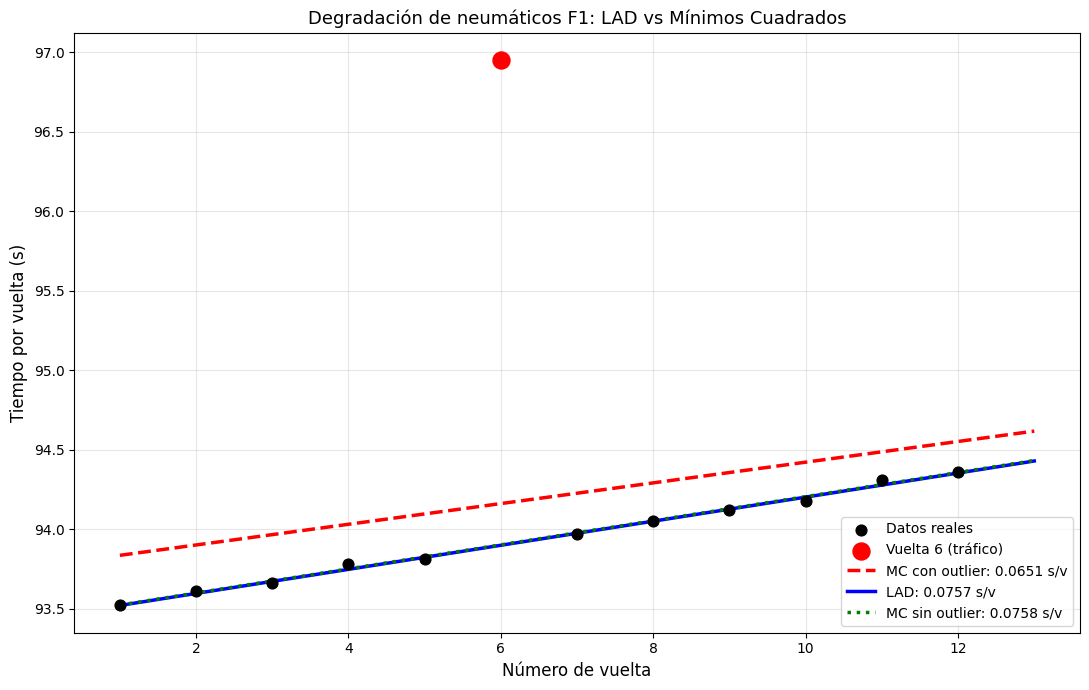


--- PASO 6: ANÁLISIS ---
MC con outlier subestima la degradación en 14.0%
  MC:  0.0651 s/vuelta
  LAD: 0.0757 s/vuelta
  MC sin outlier: 0.0758 s/vuelta

LAD prácticamente ignora el outlier y recupera la pendiente real.
El residuo de la vuelta 6 en LAD es de ~3 s, pero no afecta.

--- PASO 7: DECISIÓN DE ESTRATEGIA ---
Con degradación k y pérdida en boxes P=21 s:
  Una parada compensa si N > 2*sqrt(P/k)
  Con LAD:  N > 33.3 vueltas
  Con MC:   N > 35.9 vueltas
  Diferencia: 2.6 vueltas

El outlier cambiaría el umbral de decisión en casi 3 vueltas.

--- PASO 8: CONCLUSIÓN ---
1. LAD es robusto a outliers, ideal para datos reales de F1.
2. MC se deja arrastrar por vueltas atípicas (tráfico).
3. La decisión de parada cambia según el método usado.
4. LAD se resuelve como un problema de programación lineal.
5. En la práctica, la degradación no es lineal (cliff).


In [ ]:
# =====================================================================
# GRÁFICO: DEGRADACIÓN DE NEUMÁTICOS EN F1 (LAD vs MÍNIMOS CUADRADOS)
# =====================================================================
# CONTEXTO:
#   En F1, el tiempo por vuelta sube con el desgaste del neumático.
#   Estimar la pendiente (degradación) es clave para decidir paradas.
#   El problema: hay vueltas atípicas (tráfico) que distorsionan.
#
# SOLUCIÓN: usar regresión LAD (mínimas desviaciones absolutas) que
#   es robusta a outliers, en lugar de mínimos cuadrados.
# =====================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

print("="*70)
print("DEGRADACIÓN DE NEUMÁTICOS F1: LAD vs MÍNIMOS CUADRADOS")
print("="*70)

# ---------------------------------------------------------------------
# PASO 1: DATOS
# ---------------------------------------------------------------------
print("\n--- PASO 1: DATOS ---")
vueltas = np.arange(1, 13)
tiempos = np.array([93.52, 93.61, 93.66, 93.78, 93.81, 96.95,
                    93.97, 94.05, 94.12, 94.18, 94.31, 94.36])

print("Vuelta | Tiempo (s)")
print("-"*25)
for v, t in zip(vueltas, tiempos):
    marca = " <- OUTLIER (tráfico)" if v == 6 else ""
    print(f"  {v:>2}   |  {t:.2f}{marca}")

# ---------------------------------------------------------------------
# PASO 2: AJUSTE POR MÍNIMOS CUADRADOS (con outlier)
# ---------------------------------------------------------------------
print("\n--- PASO 2: MÍNIMOS CUADRADOS (con outlier) ---")
coef_mc = np.polyfit(vueltas, tiempos, 1)
b1_mc, b0_mc = coef_mc[0], coef_mc[1]
print(f"  β0 = {b0_mc:.4f} s")
print(f"  β1 = {b1_mc:.4f} s/vuelta")

# ---------------------------------------------------------------------
# PASO 3: AJUSTE POR MÍNIMOS CUADRADOS (sin outlier)
# ---------------------------------------------------------------------
print("\n--- PASO 3: MÍNIMOS CUADRADOS (sin outlier) ---")
mask_sin = np.ones(len(vueltas), dtype=bool)
mask_sin[5] = False
coef_mc_sin = np.polyfit(vueltas[mask_sin], tiempos[mask_sin], 1)
b1_mc_sin, b0_mc_sin = coef_mc_sin[0], coef_mc_sin[1]
print(f"  β0 = {b0_mc_sin:.4f} s")
print(f"  β1 = {b1_mc_sin:.4f} s/vuelta")

# ---------------------------------------------------------------------
# PASO 4: AJUSTE POR LAD (usando linprog)
# ---------------------------------------------------------------------
print("\n--- PASO 4: LAD (regresión robusta) ---")
print("Modelo: min Σ(u_i + v_i)")
print("s.a. (β0+ - β0-) + (β1+ - β1-)*n_i + u_i - v_i = t_i")

N = len(tiempos)
X = np.column_stack([np.ones(N), vueltas])
c_lad = np.r_[0, 0, 0, 0, np.ones(2*N)]
Aeq_lad = np.hstack([X[:, [0]], -X[:, [0]], X[:, [1]], -X[:, [1]],
                     np.eye(N), -np.eye(N)])
res_lad = linprog(c_lad, A_eq=Aeq_lad, b_eq=tiempos,
                  bounds=(0, None), method='highs')
b0_lad = res_lad.x[0] - res_lad.x[1]
b1_lad = res_lad.x[2] - res_lad.x[3]
print(f"  β0 = {b0_lad:.4f} s")
print(f"  β1 = {b1_lad:.4f} s/vuelta")

# ---------------------------------------------------------------------
# PASO 5: GRÁFICO COMPARATIVO
# ---------------------------------------------------------------------
print("\n--- PASO 5: GRÁFICO ---")

fig, ax = plt.subplots(figsize=(11, 7))

# Datos
ax.scatter(vueltas, tiempos, color='black', s=60, zorder=5,
           label='Datos reales')
ax.scatter(6, 96.95, color='red', s=150, zorder=6,
           label='Vuelta 6 (tráfico)')

# Rectas
x_line = np.linspace(1, 13, 100)
ax.plot(x_line, b0_mc + b1_mc * x_line, 'r--', linewidth=2.5,
        label=f'MC con outlier: {b1_mc:.4f} s/v')
ax.plot(x_line, b0_lad + b1_lad * x_line, 'b-', linewidth=2.5,
        label=f'LAD: {b1_lad:.4f} s/v')
ax.plot(x_line, b0_mc_sin + b1_mc_sin * x_line, 'g:', linewidth=2.5,
        label=f'MC sin outlier: {b1_mc_sin:.4f} s/v')

ax.set_xlabel('Número de vuelta', fontsize=12)
ax.set_ylabel('Tiempo por vuelta (s)', fontsize=12)
ax.set_title('Degradación de neumáticos F1: LAD vs Mínimos Cuadrados',
             fontsize=13)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=10, loc='lower right')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# PASO 6: ANÁLISIS
# ---------------------------------------------------------------------
print("\n--- PASO 6: ANÁLISIS ---")
print(f"MC con outlier subestima la degradación en "
      f"{(1 - b1_mc/b1_lad)*100:.1f}%")
print(f"  MC:  {b1_mc:.4f} s/vuelta")
print(f"  LAD: {b1_lad:.4f} s/vuelta")
print(f"  MC sin outlier: {b1_mc_sin:.4f} s/vuelta")
print("\nLAD prácticamente ignora el outlier y recupera la pendiente real.")
print("El residuo de la vuelta 6 en LAD es de ~3 s, pero no afecta.")

# ---------------------------------------------------------------------
# PASO 7: DECISIÓN DE ESTRATEGIA
# ---------------------------------------------------------------------
print("\n--- PASO 7: DECISIÓN DE ESTRATEGIA ---")
print("Con degradación k y pérdida en boxes P=21 s:")
print("  Una parada compensa si N > 2*sqrt(P/k)")
print(f"  Con LAD:  N > {2*np.sqrt(21/b1_lad):.1f} vueltas")
print(f"  Con MC:   N > {2*np.sqrt(21/b1_mc):.1f} vueltas")
print(f"  Diferencia: {2*np.sqrt(21/b1_mc) - 2*np.sqrt(21/b1_lad):.1f} vueltas")
print("\nEl outlier cambiaría el umbral de decisión en casi 3 vueltas.")

# ---------------------------------------------------------------------
# PASO 8: CONCLUSIÓN
# ---------------------------------------------------------------------
print("\n--- PASO 8: CONCLUSIÓN ---")
print("1. LAD es robusto a outliers, ideal para datos reales de F1.")
print("2. MC se deja arrastrar por vueltas atípicas (tráfico).")
print("3. La decisión de parada cambia según el método usado.")
print("4. LAD se resuelve como un problema de programación lineal.")
print("5. En la práctica, la degradación no es lineal (cliff).")
print("="*70)